In [7]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

In [8]:
#==================================#
   #REGRESION LOGISTICA BINARIA#
#==================================#

# 1. Cargar datos
iris = load_iris()
X = iris.data  # Las 4 variables: largo/ancho sépalo y largo/ancho pétalo
y = iris.target

# 2. Transformar a Clasificación Binaria
# En el dataset original: Setosa=0, Versicolor=1, Virginica=2
# Queremos que Virginica (2) sea 1, y todo lo demás sea 0
y_binario = (y == 2).astype(int) 

# 3. División de datos (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y_binario, test_size=0.2, random_state=42)

# 4. Crear y entrenar el modelo de Regresión Logística
modelo = LogisticRegression()
modelo.fit(X_train, y_train)

# 5. Predicciones
predicciones = modelo.predict(X_test)
probabilidades = modelo.predict_proba(X_test)[:, 1] # Probabilidad de ser Virginica

# 6. Evaluación
print(f"Precisión del modelo: {accuracy_score(y_test, predicciones):.2%}")
print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, predicciones))

# Ejemplo: Probar con una flor inventada (L.Sépalo, A.Sépalo, L.Pétalo, A.Pétalo)
nueva_flor = np.array([[6.5, 3.0, 5.5, 2.0]]) 
resultado = modelo.predict(nueva_flor)
prob = modelo.predict_proba(nueva_flor)[0][1]

print(f"\nResultado para la nueva flor: {'Es Virginica' if resultado[0] == 1 else 'No es Virginica'}")
print(f"Probabilidad de que sea Virginica: {prob:.2%}")

Precisión del modelo: 100.00%

Matriz de Confusión:
[[19  0]
 [ 0 11]]

Resultado para la nueva flor: Es Virginica
Probabilidad de que sea Virginica: 90.22%


C:\Users\nehem\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



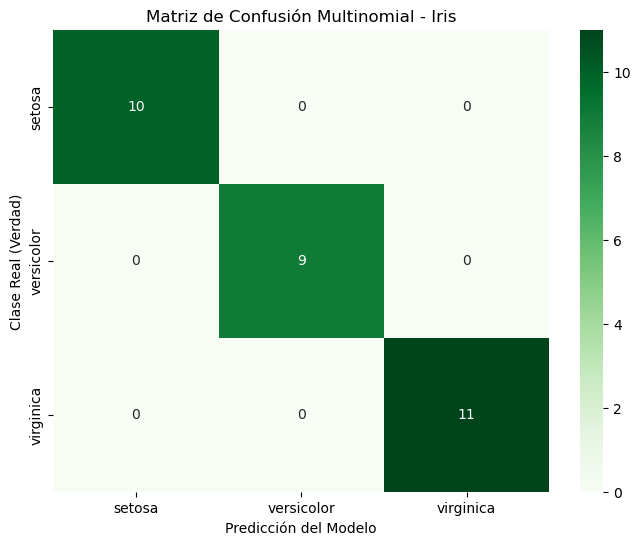

In [2]:
#==================================#
 #REGRESION LOGISTICA MULTINOMINAL#
#==================================#
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Cargar el dataset completo
iris = load_iris()
X = iris.data
y = iris.target # Aquí 'y' tiene valores 0, 1 y 2

# 2. Dividir datos (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Configurar Regresión Logística Multinomial
# multi_class='multinomial' es el estándar moderno, lbfgs es el optimizador que lo soporta
modelo_multi = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=200)
modelo_multi.fit(X_train, y_train)

# 4. Predicciones
y_pred = modelo_multi.predict(X_test)

# 5. Evaluación detallada
print("--- REPORTE DE CLASIFICACIÓN ---")
# Esto nos dará Precision, Recall y F1-Score para CADA especie
print(classification_report(y_test, y_pred, target_names=iris.target_names))

# 6. Matriz de Confusión 3x3
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicción del Modelo')
plt.ylabel('Clase Real (Verdad)')
plt.title('Matriz de Confusión Multinomial - Iris')
plt.show()